# Sliding Window Dual Analysis: Correlation vs. Causality

This notebook takes a rigorous, dual-method approach to exploring dynamic network changes.
It calculates a rolling window (e.g., 10 seconds) and slides it across the peri-event time.

**Top Plot (Correlation)**: A simple, highly stable metric (Pearson R) proving *that* the relationship changes.
**Bottom Plot (Causality)**: A complex, directional metric (VARLiNGAM) suggesting the *direction* of the change.

*Note on Statistical Limitations*: VARLiNGAM relies on detecting non-Gaussianity via ICA, which typically requires thousands of data points to be stable. A 10-second window only contains 200 data points (at 20 FPS). Therefore, the causality estimates here are directional hypotheses and should be interpreted alongside the simple correlation.

In [69]:
import sys
from pathlib import Path
import pickle
import numpy as np
import pandas as pd
from tqdm import tqdm
import matplotlib.pyplot as plt
import joblib
from scipy.signal import find_peaks

# Add project root to path
try:
    project_root = Path(__file__).resolve().parents[2]
except NameError:
    project_root = Path("../../").resolve()
    
if str(project_root) not in sys.path:
    sys.path.append(str(project_root))

from monoamine_interactions.notebooks.utils.photometry import motion_correct_biexponential
from monoamine_interactions.analysis.phase_1_causality import varlingam

In [70]:
# CONFIGURATION
# Set to a specific key (e.g., "juvenile_first_sniff_min") or "all" to plot everything.
EVENT_KEY = "all" 
PRE_SEC = 20
POST_SEC = 40

# Windowing Parameters
SLIDING_WINDOW_SEC = 10 
STRIDE_SEC = 0.5       # Slides by 0.5s to reduce overlap slightly while keeping smooth kinetics
N_JOBS = -1            
LAG = 5                
FPS = 20

# Peak Detection Sensitivity (Adjust these to show more/fewer dots)
PEAK_PROMINENCE_CORR = 0.15   # Minimum height of a peak/valley relative to its base for Correlation
PEAK_PROMINENCE_CAUS = 0.05   # Minimum height of a peak/valley relative to its base for Causality
PEAK_DISTANCE_SEC = 2.0       # Minimum horizontal distance (seconds) between peaks

frames_calc_window = int(SLIDING_WINDOW_SEC * FPS)
frames_stride = int(STRIDE_SEC * FPS)

# Target specific pairs to avoid combinatorial explosion. 
SELECTED_PAIRS = [
    ("lNAc_5HT", "rNAc_DA"),
    ("rNAc_DA", "lNAc_5HT"),
    ("lNAc_DA", "rNAc_5HT"),
    ("rNAc_5HT", "lNAc_DA")
]

pkl_path = project_root / "monoamine_interactions" / "data" / "sessions_jonathan_juvenile_intruder_dirty.pkl"

In [71]:
# 1. Load Data
print(f"Loading {pkl_path}...")
with open(pkl_path, "rb") as f:
    sessions = pickle.load(f)

# Deduplicate sessions
unique_sessions = []
seen_csvs = set()
for s in sessions:
    csv_path = s.metadata.get('photometry_csv_path')
    if csv_path and csv_path not in seen_csvs:
        seen_csvs.add(csv_path)
        unique_sessions.append(s)
sessions = unique_sessions
print(f"Post-deduplication: {len(sessions)} unique biological sessions.")

# Identify all available events
all_events = set()
for s in sessions:
    all_events.update(s.metadata.get('timing_meta', {}).keys())
all_events = sorted(list(all_events))

events_to_process = all_events if EVENT_KEY == "all" else [EVENT_KEY]
print(f"Processing events: {events_to_process}")

Loading /home/fsp585/Desktop/FiberphotometryCode/monoamine_interactions/data/sessions_jonathan_juvenile_intruder_dirty.pkl...
Post-deduplication: 10 unique biological sessions.
Processing events: ['home_cage_min', 'homecage_removed_min', 'inarena_min', 'juvenile_first_sniff_min', 'juvenile_removed_min']


In [72]:
# 2. Worker Functions
def run_windowed_metrics(chunk, regs):
    """Worker function for parallel processing. Calculates both Correlation and Causality."""
    clean_chunk = chunk.dropna()
    if len(clean_chunk) < frames_calc_window * 0.8:
        return None
    
    metrics = {'corr': {}, 'causal': {}}
    
    # 1. Pearson Correlation (Undirected)
    corr_matrix = clean_chunk.corr().values
    
    # 2. VARLiNGAM Causality (Directed)
    try:
        res = varlingam.run_varlingam(clean_chunk, lags=LAG)
        adj = res["adjacency_matrices"][0]
        success_var = True
    except:
        adj = None
        success_var = False
        
    for i, r1 in enumerate(regs):
        for j, r2 in enumerate(regs):
            if i == j: continue
            
            # Correlation is symmetric, just store it under the directed tuple for consistency
            metrics['corr'][(r1, r2)] = corr_matrix[i, j]
            
            if success_var:
                metrics['causal'][(r2, r1)] = adj[i, j] # Note: adj[i,j] is usually source j -> target i
            else:
                metrics['causal'][(r2, r1)] = np.nan
                
    return metrics

In [73]:
# 3. Extract and Process Sliding Windows
all_results = []
metadata_per_event = {} 

for event in events_to_process:
    print(f"\nProcessing event: {event}")
    expected_length = None
    time_vec = None
    
    for s in tqdm(sessions, desc=f"Extracting {event}"):
        tm = s.metadata.get("timing_meta", {})
        t_event_min = tm.get(event)
        if pd.isna(t_event_min): 
            continue
            
        if '470' not in s.photometry: continue
            
        df_470 = s.photometry['470']
        df_415 = s.photometry['415']
        ts_array = df_470['SystemTimestamp'].values
        
        t_start_sys = ts_array[0]
        target_ts_event = t_start_sys + (t_event_min * 60)
        
        start_idx = np.abs(ts_array - (target_ts_event - PRE_SEC)).argmin()
        end_idx = np.abs(ts_array - (target_ts_event + POST_SEC)).argmin()
        
        if end_idx <= start_idx: continue
            
        curr_len = end_idx - start_idx
        if expected_length is None:
            expected_length = curr_len
            
        if curr_len != expected_length:
            end_idx = start_idx + expected_length
            if end_idx > len(ts_array): continue 

        genotype = s.metadata.get('genotype', 'Unknown')
        sm = s.metadata.get("signal_meta", {})
        region_map = {k: v.get("region") for k, v in sm.items() if v.get("region")}
        
        dff_dict = {}
        for r in region_map.values():
            try:
                col = next((k for k, v in region_map.items() if v == r))
                full_dff = motion_correct_biexponential(df_470[col].values, df_415[col].values)
                dff_dict[r] = full_dff
            except: pass
            
        valid_regs = list(dff_dict.keys())
        if len(valid_regs) < 2: continue
        
        # Chunk the data
        chunks = []
        peth_times = []
        
        for i in range(start_idx + frames_calc_window, end_idx, frames_stride):
            chunk_center_idx = i - (frames_calc_window // 2)
            rel_time_sec = (ts_array[chunk_center_idx] - target_ts_event) / 60.0 * 60.0 
            
            chunk = pd.DataFrame({r: dff_dict[r][i-frames_calc_window:i] for r in valid_regs})
            chunks.append(chunk)
            peth_times.append(rel_time_sec)
            
        if time_vec is None:
            time_vec = np.array(peth_times)
            metadata_per_event[event] = {'time_vec': time_vec}

        # Parallel process chunks
        chunk_results = joblib.Parallel(n_jobs=N_JOBS)(
            joblib.delayed(run_windowed_metrics)(c, valid_regs) for c in chunks
        )
        
        # Unpack results
        for pair in SELECTED_PAIRS:
            if pair[0] not in valid_regs or pair[1] not in valid_regs:
                continue
                
            corr_series = []
            causal_series = []
            
            for res in chunk_results:
                if res is not None:
                    corr_val = res['corr'].get((pair[0], pair[1]), np.nan)
                    if pd.isna(corr_val): corr_val = res['corr'].get((pair[1], pair[0]), np.nan)
                    caus_val = res['causal'].get(pair, np.nan)
                    corr_series.append(corr_val)
                    causal_series.append(caus_val)
                else:
                    corr_series.append(np.nan)
                    causal_series.append(np.nan)
                    
            interp_corr = np.interp(time_vec, peth_times, corr_series)
            interp_causal = np.interp(time_vec, peth_times, causal_series)
            
            all_results.append({
                'event': event,
                'genotype': genotype,
                'source': pair[0],
                'target': pair[1],
                'corr_array': interp_corr,
                'causal_array': interp_causal
            })

df_results = pd.DataFrame(all_results)
print(f"Extracted {len(df_results)} valid pair traces total.")

from scipy.ndimage import gaussian_filter1d


Processing event: home_cage_min


Extracting home_cage_min: 100%|██████████| 10/10 [00:04<00:00,  2.24it/s]



Processing event: homecage_removed_min


Extracting homecage_removed_min: 100%|██████████| 10/10 [00:02<00:00,  4.03it/s]



Processing event: inarena_min


...


Processing event: juvenile_first_sniff_min


Extracting juvenile_first_sniff_min: 100%|██████████| 10/10 [00:02<00:00,  4.09it/s]



Processing event: juvenile_removed_min


Extracting juvenile_removed_min: 100%|██████████| 10/10 [00:02<00:00,  4.06it/s]

Extracted 30 valid pair traces total.


In [74]:
# 4. Plotting Dual Analysis
def plot_dual_peth(df, groupby_cols, title, filename, event_name, threshold=0.01):
    # Filter by event
    df_ev = df[df['event'] == event_name]
    if len(df_ev) == 0: return
    
    time_vec = metadata_per_event[event_name]['time_vec']
    
    valid_groups = []
    
    # We want these exact pairs in this exact order so reciprocals are adjacent
    canonical_pairs = [
        ("lNAc_5HT", "rNAc_DA"),
        ("rNAc_DA", "lNAc_5HT"),
        ("lNAc_DA", "rNAc_5HT"),
        ("rNAc_5HT", "lNAc_DA")
    ]
    
    # Pre-calculate means and order them nicely
    for genotype, g_df in df_ev.groupby('genotype'):
        for pair in canonical_pairs:
            source, target = pair
            pair_df = g_df[(g_df['source'] == source) & (g_df['target'] == target)]
            if len(pair_df) == 0: continue
            
            caus_arrays = np.vstack(pair_df['causal_array'].values)
            mean_caus = np.nanmean(caus_arrays, axis=0)
            
            # If the max absolute weight is below threshold, skip it
            if np.nanmax(np.abs(mean_caus)) > threshold:
                name = (genotype, source, target)
                valid_groups.append((name, pair_df, mean_caus))
            
    if len(valid_groups) == 0: 
        print(f"Skipping {event_name}: No groups passed the causality threshold of {threshold}.")
        return
    
    n_groups = len(valid_groups)
    fig, axes = plt.subplots(n_groups, 1, figsize=(10, 3 * n_groups), sharex=True)
    
    # Handle single group case where subplots returns a flat array
    if n_groups == 1:
        axes = np.array([axes]) 
        
    for i, (name, group, mean_caus) in enumerate(valid_groups):
        ax_caus = axes[i]
        genotype, source, target = name
        label = f"{genotype} | {source} -> {target}"
            
        caus_arrays = np.vstack(group['causal_array'].values)
        std_caus = np.nanstd(caus_arrays, axis=0) / np.sqrt(len(caus_arrays))
        
        # --- Plot Causality ---
        line = ax_caus.plot(time_vec, mean_caus, label=label, linewidth=2, color=f"C{i}")
        ax_caus.fill_between(time_vec, mean_caus - std_caus, mean_caus + std_caus, alpha=0.2, color=line[0].get_color())
        
        # Detect Peaks and Valleys for Causality
        dist_frames = max(1, int(PEAK_DISTANCE_SEC / STRIDE_SEC))
        p_caus, _ = find_peaks(mean_caus, prominence=PEAK_PROMINENCE_CAUS, distance=dist_frames)
        v_caus, _ = find_peaks(-mean_caus, prominence=PEAK_PROMINENCE_CAUS, distance=dist_frames)
        ax_caus.scatter(time_vec[p_caus], mean_caus[p_caus], color='red', s=40, zorder=5)
        ax_caus.scatter(time_vec[v_caus], mean_caus[v_caus], color='red', s=40, zorder=5)
        
        ax_caus.axvline(0, color='black', linestyle='--')
        ax_caus.set_ylabel(f"Causal Weight")
        ax_caus.set_title(label)
        ax_caus.grid(True, alpha=0.3)
        ax_caus.legend(loc='upper right')
        
    # Clean up event name for display (remove _min and replace underscores)
    display_name = event_name.replace('_min', '').replace('_', ' ').title()
    
    axes[-1].set_xlabel(f"Time relative to {display_name} (s)")
    plt.suptitle(f"{title} - {display_name}", y=1.02, fontsize=14)
    plt.tight_layout()
    
    # Save to outputs dir
    out_dir = project_root / "monoamine_interactions" / "outputs" / "05_sliding_causality"
    out_dir.mkdir(parents=True, exist_ok=True)
    plt.savefig(out_dir / filename)
    plt.show()

## Side-by-Side Validation Plots


--- GENERATING DUAL PLOTS FOR EVENT: home_cage_min ---


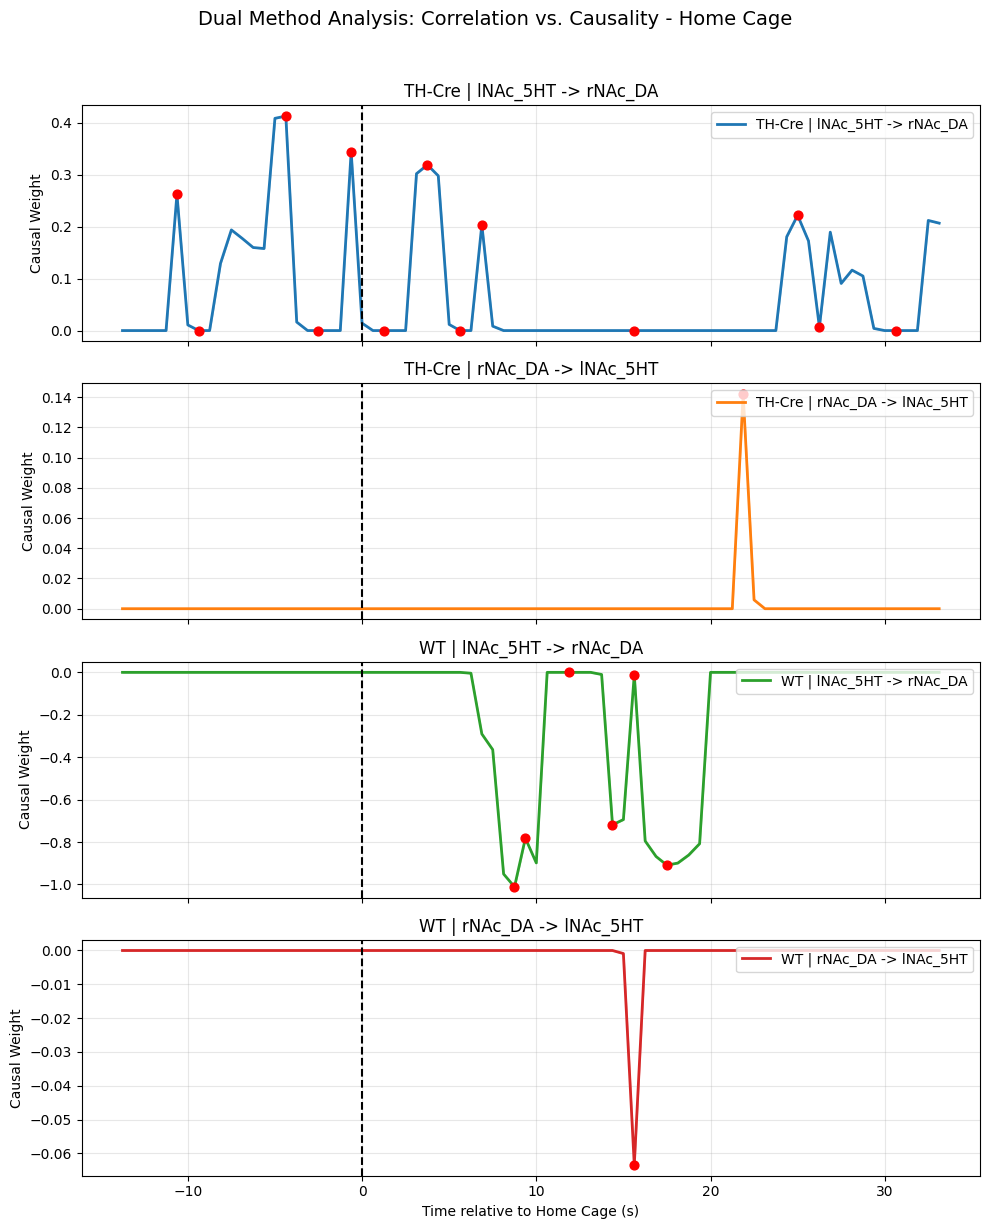


--- GENERATING DUAL PLOTS FOR EVENT: homecage_removed_min ---


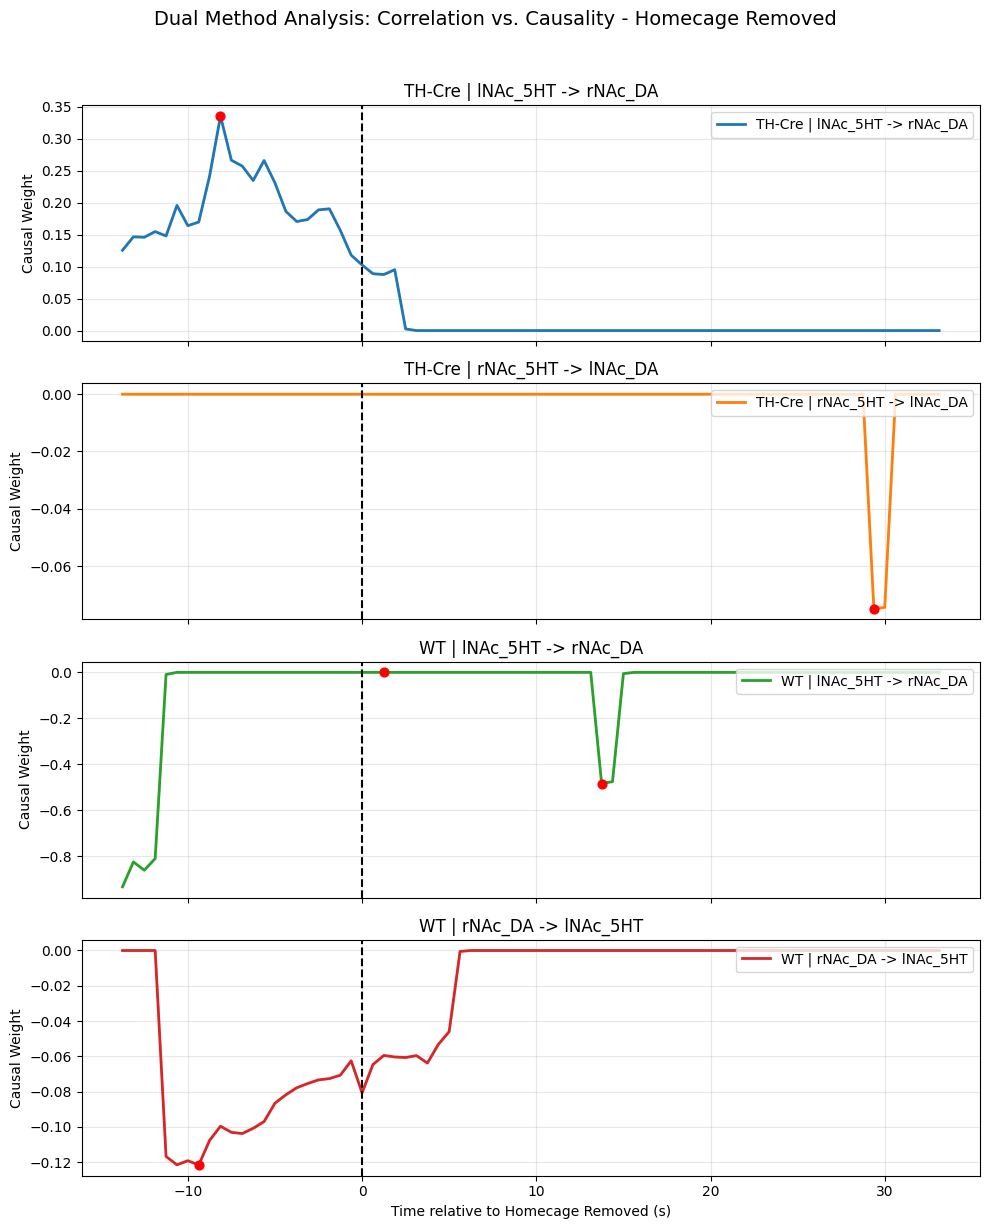


--- GENERATING DUAL PLOTS FOR EVENT: inarena_min ---


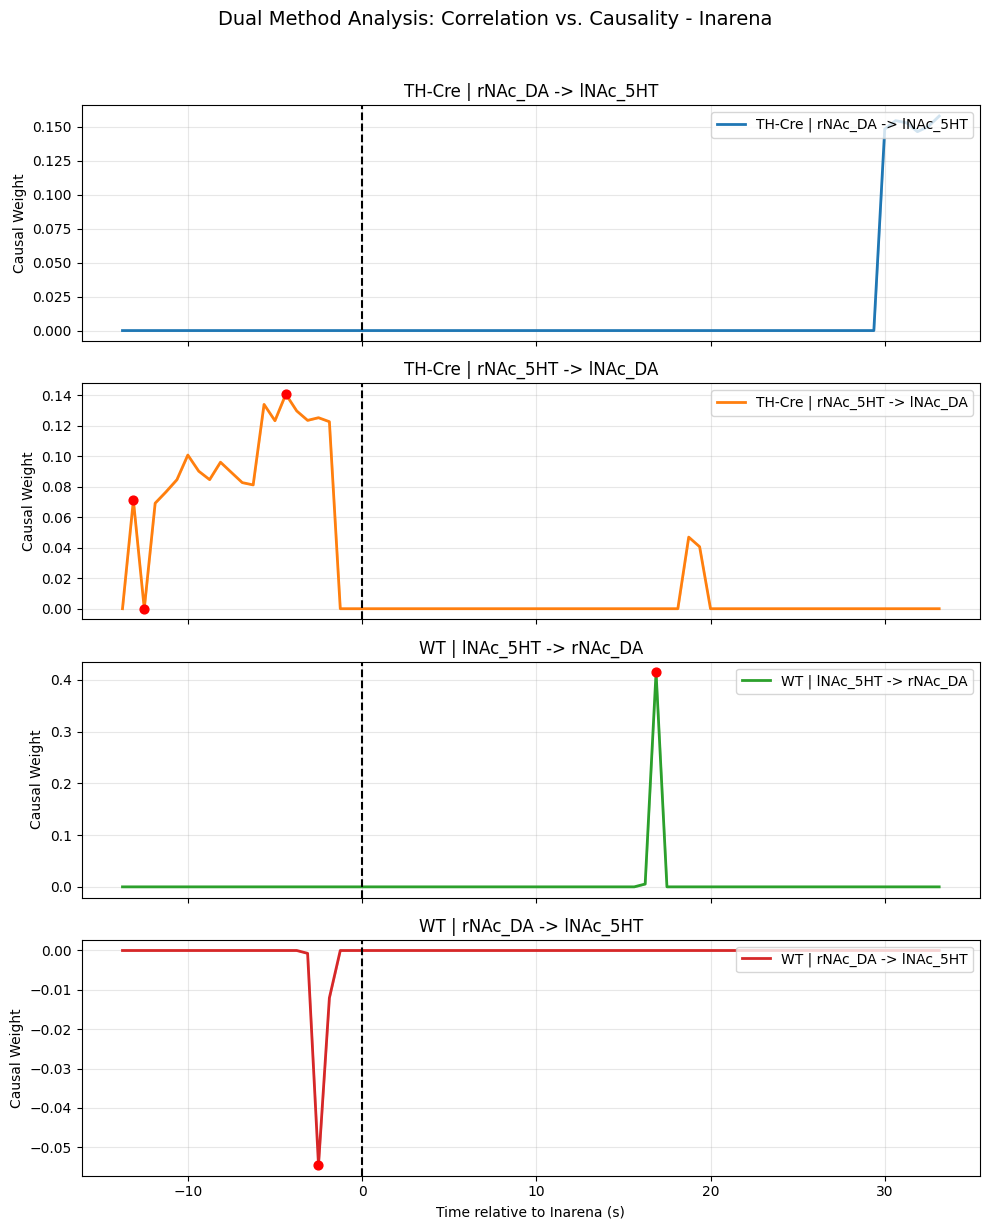


--- GENERATING DUAL PLOTS FOR EVENT: juvenile_first_sniff_min ---


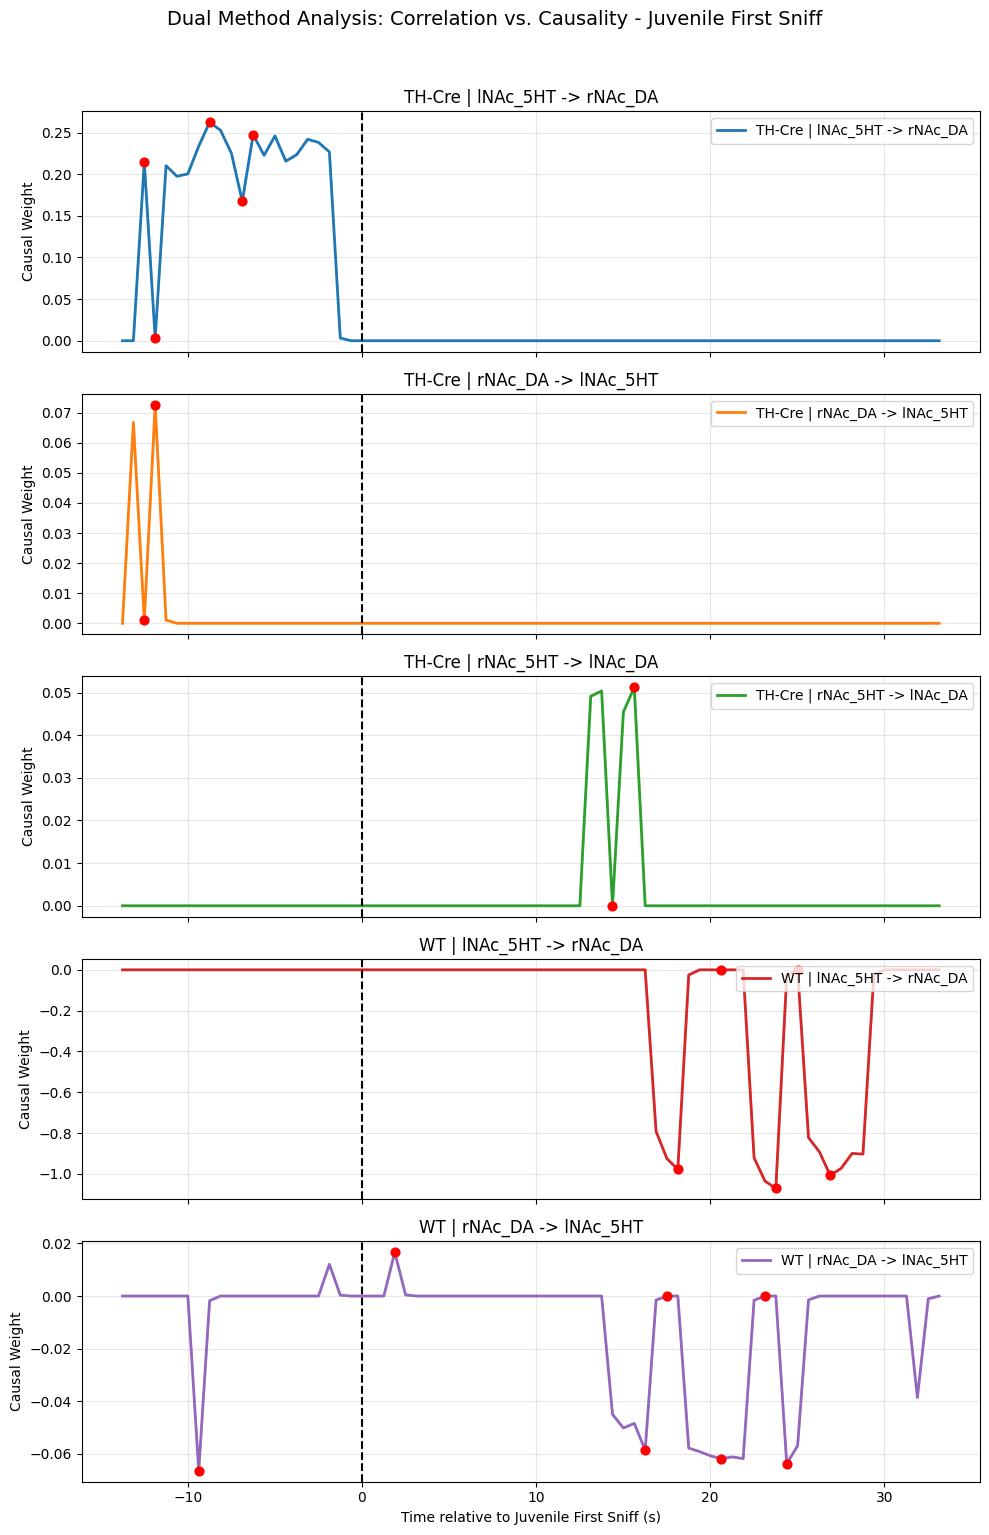


--- GENERATING DUAL PLOTS FOR EVENT: juvenile_removed_min ---


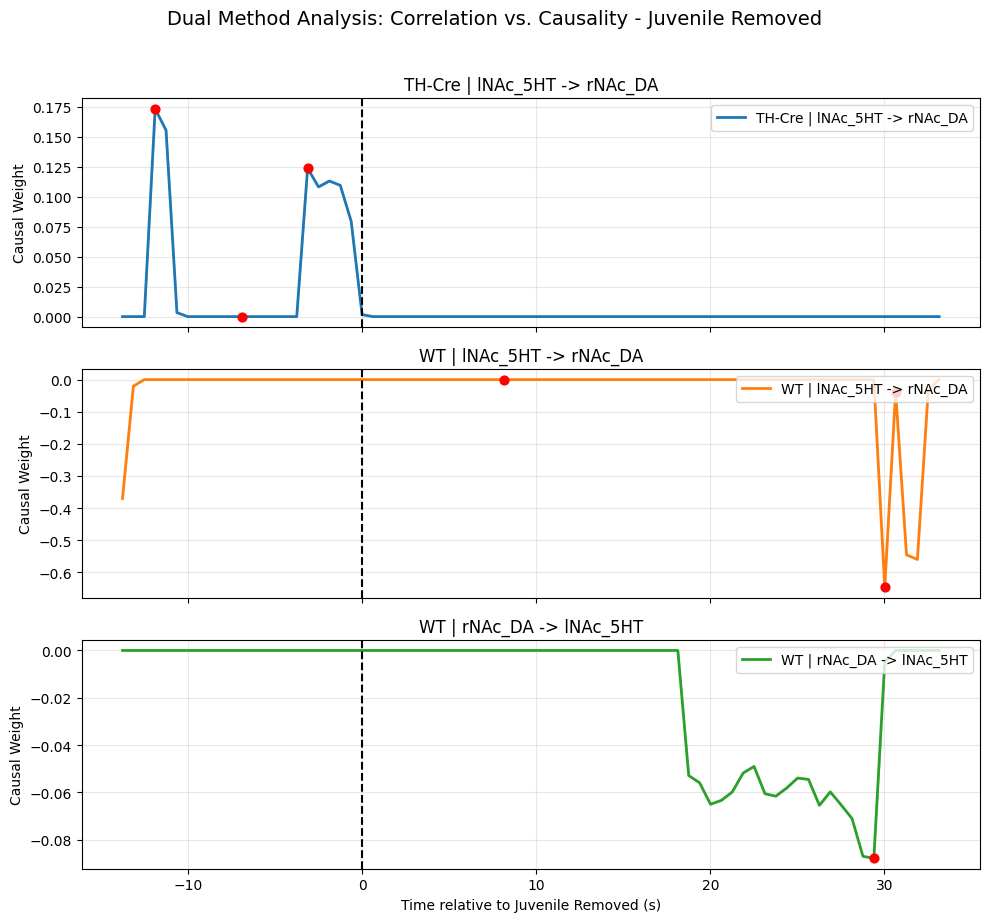

In [75]:
if len(df_results) > 0:
    for event in df_results['event'].unique():
        print(f"\n--- GENERATING DUAL PLOTS FOR EVENT: {event} ---")
        plot_dual_peth(df_results, ['genotype', 'source', 'target'], "Dual Method Analysis: Correlation vs. Causality", f"05_dual_causality_{event}.png", event)
else:
    print("No matching pairs found in the dataset.")